In [1]:
import numpy as np
import matplotlib.pyplot as plt 

import pandas as pd  
import seaborn as sns 
from sklearn import metrics
import scipy.io as sio
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
import warnings
warnings.filterwarnings('ignore')
import xarray as xr
from sklearn.preprocessing import PolynomialFeatures

In [2]:
## training data

week = '2'

file_path_obs_train = f'IMD_Data/Week{week}/IMD_pra_1989-2010.nc'
file_path_model_train = f'IMD_Data/Week{week}/GEFS_pra_1989-2010.nc'
data_obs_train = xr.open_dataset(file_path_obs_train)
data_model_train = xr.open_dataset(file_path_model_train)

## test data

file_path_obs_test = f'IMD_Data/Week{week}/IMD_pra_2011-2018.nc'
file_path_model_test = f'IMD_Data/Week{week}/GEFS_pra_2011-2018.nc'
data_obs_test = xr.open_dataset(file_path_obs_test)
data_model_test = xr.open_dataset(file_path_model_test)

In [3]:
train_obs_values = data_obs_train['prcp'].values
train_model_values = data_model_train.mean('M')['prcp'].values

In [4]:
test_obs_values = data_obs_test['prcp'].values
test_model_values = data_model_test.mean('M')['prcp'].values

In [5]:
np.isnan(test_obs_values).sum()

95056

In [6]:
train_obs_values.shape

(386, 32, 31)

In [7]:
assert train_obs_values.shape == train_model_values.shape

In [8]:
test_obs_values.shape

(140, 32, 31)

In [9]:
y = np.concatenate([train_obs_values, test_obs_values], axis=0)
X = np.concatenate([train_model_values, test_model_values], axis=0)

In [10]:
X.shape

(526, 32, 31)

In [11]:
y.shape

(526, 32, 31)

In [12]:
np.isnan(y[:,4,10]).sum()

0

In [13]:
test_obs_values[:,3,8]

array([ 8.5838175 , 15.157028  , 12.576152  ,  3.1389902 , 14.794938  ,
       22.035194  ,  9.308097  ,  7.4956503 , 22.035488  , 13.122151  ,
        7.732906  ,  5.181859  , 24.38267   , 16.554552  , 10.821521  ,
        1.5137118 ,  0.31807888,  0.        , 20.936802  ,  4.049583  ,
       14.751153  , 11.429258  ,  9.721317  ,  5.6275473 ,  3.990741  ,
        3.3656397 , 13.096393  , 17.8356    , 11.0499525 , 18.152287  ,
        8.595789  , 10.62513   ,  1.8157976 ,  0.5771536 ,  0.13290091,
       52.34255   , 40.73449   , 22.541817  , 25.990337  , 21.325495  ,
       29.526743  , 16.13083   , 40.647003  ,  2.1720061 ,  5.557697  ,
        3.3832943 ,  0.        ,  7.5973015 , 19.411259  ,  8.007972  ,
        1.5778193 ,  4.2072477 , 34.73617   , 20.321817  ,  9.896679  ,
        6.434012  , 36.30613   , 17.283737  , 19.40897   , 44.502647  ,
       30.864128  ,  2.7069936 , 21.089533  , 30.791529  , 13.349001  ,
        5.912586  ,  2.947972  ,  8.588899  ,  7.1704874 , 18.64

In [14]:
assert y.shape == X.shape

In [15]:
test_indices = np.random.choice(list(range(526)), 140, replace=False)

In [16]:
mask = np.ones(X.shape[0], dtype=bool)
mask[test_indices] = False

In [17]:
np.sum(mask)

386

In [18]:
X_test = X[~mask, :, :]

In [19]:
X_test.shape

(140, 32, 31)

In [20]:
X_train = X[mask, :, :]

In [21]:
X_train.shape

(386, 32, 31)

In [22]:
y_train = y[mask, :, :]
y_test = y[~mask, :, :]

In [23]:
assert y_train.shape[0]==X_train.shape[0]

In [24]:
y_train.shape

(386, 32, 31)

In [25]:
y_test.shape

(140, 32, 31)

In [26]:
import json
import ast

# Read dictionary from a JSON file
with open('best_params_1.json', 'r') as json_file:
    params_str_keys = json.load(json_file)

# Convert string keys back to tuples
best_params_prop = {ast.literal_eval(k): v for k, v in params_str_keys.items()}

In [27]:
# Read dictionary from a JSON file
with open('best_params_extr_1.json', 'r') as json_file:
    params_str_keys = json.load(json_file)

# Convert string keys back to tuples
best_params_prop1 = {ast.literal_eval(k): v for k, v in params_str_keys.items()}

In [28]:
len(best_params_prop)

316

In [29]:
len(best_params_prop1)

76

In [30]:
for i in best_params_prop1:
    best_params_prop[i] = best_params_prop1[i]

In [31]:
best_params_prop

{(2, 9): {'mss': 55, 'ne': 35, 'b_rpss': 0.07729153948792},
 (2, 10): {'mss': 55, 'ne': 21, 'b_rpss': 0.043267651273681706},
 (3, 8): {'mss': 41, 'ne': 35, 'b_rpss': 0.12150320565383632},
 (3, 9): {'mss': 54, 'ne': 34, 'b_rpss': 0.13213651326641151},
 (3, 10): {'mss': 55, 'ne': 26, 'b_rpss': 0.1408268919233142},
 (3, 11): {'mss': 55, 'ne': 27, 'b_rpss': 0.029599765681499912},
 (4, 8): {'mss': 53, 'ne': 34, 'b_rpss': 0.306341620743529},
 (4, 9): {'mss': 75, 'ne': 53, 'b_rpss': 0.048239184228277},
 (4, 10): {'mss': 55, 'ne': 20, 'b_rpss': 0.13067703505745554},
 (4, 11): {'mss': 40, 'ne': 35, 'b_rpss': 0.0508671482003662},
 (5, 7): {'mss': 45, 'ne': 32, 'b_rpss': 0.09439351244200667},
 (5, 8): {'mss': 55, 'ne': 33, 'b_rpss': 0.04646424400896032},
 (5, 9): {'mss': 55, 'ne': 29, 'b_rpss': 0.13029497035147142},
 (5, 10): {'mss': 55, 'ne': 34, 'b_rpss': 0.23592846303590442},
 (5, 11): {'mss': 55, 'ne': 35, 'b_rpss': 0.20439244697567105},
 (6, 7): {'mss': 55, 'ne': 33, 'b_rpss': 0.082493595956

In [26]:
def rps_clim(class_value):
    
    if len(class_value.shape)>1:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_clim_probs = np.cumsum(np.ones((class_value.shape[0],3))*0.3333, axis=1).round(3)
        values = ((cum_clim_probs-cum_obs)**2)/(class_value.shape[1]-1)
    else:
        cum_obs = np.cumsum(class_value, axis=0)
        cum_clim_probs = np.cumsum(np.ones(3)*0.3333, axis=0).round(3)
        values = ((cum_clim_probs-cum_obs)**2)/(class_value.shape[0]-1)
    
    
    if len(class_value.shape)>1:
        return np.mean(np.sum(values, axis=1))
    else:
        return np.sum(values)
    
def rps_forecast(class_value, probs, grid_point=None):
    """
    grid_point: optional if only a single point is being fed as an input
    """
    if grid_point is not None:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_fc_probs = np.cumsum(probs[grid_point[0], grid_point[1]], axis=1).round(3)
        values = ((cum_fc_probs-cum_obs)**2)/(class_value.shape[1]-1)
    else:
        cum_obs = np.cumsum(class_value, axis=1)
        cum_fc_probs = np.cumsum(probs, axis=1).round(3)
        values = ((cum_fc_probs-cum_obs)**2)/(class_value.shape[1]-1)
        
    
    if len(class_value.shape)>1:
        return np.mean(np.sum(values, axis=1))
    else:
        return np.sum(values)
    
def make_ohe(array):
    p_33 = np.quantile(array, q=1/3)
    p_67 = np.quantile(array, q=2/3)
    
    ohe = np.zeros((array.shape[0],3))
    for i in range(len(array)):
        if array[i]<=p_33:
            ohe[i][0] = 1
        elif p_33<array[i]<=p_67:
            ohe[i][1] = 1
        elif array[i]>p_67:
            ohe[i][2] = 1
    
    return ohe, p_33, p_67

In [27]:
def get_tercile_predictions_single_grid(observed_data_train, model_output_train, observed_data_test, model_output_test,
                                       mss, ne):
    '''
    Generate tercile probability predictions for observed test data based on a fitted quantile regression model for a single grid point.

    Parameters:
    observed_data_train (np.ndarray): 1D array containing the observed training data for a single grid point.
    model_output_train (np.ndarray): 1D array of model output for training for a single grid point.
    observed_data_test (np.ndarray): 1D array containing the observed testing data for a single grid point.
    model_output_test (np.ndarray): 1D array of model output for testing for a single grid point.

    Returns:
    np.ndarray: A 2D array of shape (number of test data points, 3), where each element contains the probabilities of falling into the lower, middle, and upper terciles.
    '''
    
    quantiles = np.linspace(0, 100, 40)
    
    ts_grid_ij_obs_train = observed_data_train
    ts_grid_ij_model_train = model_output_train
    ts_grid_ij_obs_test = observed_data_test
    ts_grid_ij_model_test = model_output_test

    if np.all(np.isnan(ts_grid_ij_obs_train)):
        return np.zeros((ts_grid_ij_obs_test.shape[0], 3))  # Return zeros if training data is all NaNs

    X_train = ts_grid_ij_model_train.reshape(-1, 1)
    y_train = ts_grid_ij_obs_train
    X_test = ts_grid_ij_model_test.reshape(-1, 1)
    y_test = ts_grid_ij_obs_test

    # Train the model
    rfqr = RandomForestQuantileRegressor(random_state=0, min_samples_split=mss, n_estimators=ne)
    rfqr.fit(X_train, y_train)

    # Predict quantiles for test data
    pred_test_quantiles = [rfqr.predict(X_test, quantile=q).reshape(-1, 1) for q in quantiles]
    q_preds_test = np.concatenate(pred_test_quantiles, axis=1)
    
    # Construct reference CDF
    reference_cdf = np.interp(np.linspace(np.min(ts_grid_ij_obs_train), np.max(ts_grid_ij_obs_train), y_test.shape[0]), 
                              np.quantile(y_train, np.linspace(0, 100, y_train.shape[0]) / 100), 
                              np.linspace(0, 100, y_train.shape[0]) / 100, left=0, right=1)

    # Calculate individual CDFs for each test point
    individual_cdfs = np.zeros((y_test.shape[0], y_test.shape[0]))
    for k in range(y_test.shape[0]):
        xp_k = q_preds_test[k, :]
        cdf_k = np.interp(np.linspace(np.min(xp_k), np.max(xp_k), y_test.shape[0]), 
                          xp_k, np.linspace(0, 100, 40) / 100, left=0, right=1)
        individual_cdfs[k, :] = cdf_k  # CDF for each point

    p1, p2 = 0.333, 0.667

    # Calculate the absolute difference from the specific value
    absolute_difference_from_value_1 = np.abs(reference_cdf - p1)
    absolute_difference_from_value_2 = np.abs(reference_cdf - p2)

    # Find the index of the minimum difference
    index_of_value_p33_ref = np.argmin(absolute_difference_from_value_1)
    index_of_value_p67_ref = np.argmin(absolute_difference_from_value_2)

    # Obtain the tercile predictions
    triplet_array = np.zeros((y_test.shape[0], 3))
    for k in range(y_test.shape[0]):
        # Take the correct individual CDF
        p_bn = individual_cdfs[k, :][index_of_value_p33_ref]
        p_n = individual_cdfs[k, :][index_of_value_p67_ref] - p_bn
        p_an = 1 - p_n - p_bn

        triplet_array[k, 0], triplet_array[k, 1], triplet_array[k, 2] = p_bn, p_n, p_an

    return triplet_array

In [28]:
from tqdm import tqdm
from skgarden import RandomForestQuantileRegressor

In [35]:
new_rpss_mat = np.full((32,31), np.nan)
for i in tqdm(best_params_prop):
    try:
        if np.all(np.isnan(y_train[:, i[0], i[1]])):
            print(f"Skipping {i[0], i[1]} as null...")
            continue
        ohe, _, _ = make_ohe(y_test[:, i[0], i[1]])
        rps_c = rps_clim(ohe)
        ms, n = best_params_prop[(i[0],i[1])]['mss'], best_params_prop[(i[0],i[1])]['ne']
        tp = get_tercile_predictions_single_grid(
            y_train[:, i[0], i[1]], 
            X_train[:, i[0], i[1]], 
            y_test[:, i[0], i[1]], 
            X_test[:, i[0], i[1]], ms, n
        )
        rps_fc = rps_forecast(ohe, tp)
        new_rpss_mat[i[0], i[1]] = 1 - (rps_fc / rps_c)
    except:
        new_rpss_mat[i[0], i[1]] = 0
        continue

100%|█████████████████████████████████████████| 316/316 [02:21<00:00,  2.23it/s]


In [36]:
index = np.argwhere(new_rpss_mat==0)

In [37]:
index

array([[ 3,  8],
       [ 5,  7],
       [ 8,  6],
       [11,  5],
       [14,  2],
       [15,  1],
       [15, 25],
       [17,  0],
       [19,  2],
       [20, 20],
       [20, 22],
       [21,  2],
       [21,  3],
       [21, 20],
       [22, 26]])

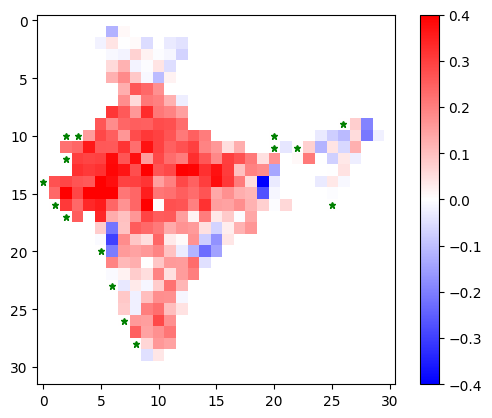

In [38]:
plt.imshow(np.flip(new_rpss_mat, axis=0), cmap='bwr', vmin=-0.4, vmax=0.4)
for i in index:
    plt.plot(i[1], 31-i[0], 'g*', markersize=5)
plt.colorbar()

In [83]:
week_2_old_rpss = np.load("./RPSS - Scores/IMD_2/rpss_imd_2_n20_mss_50.npy")

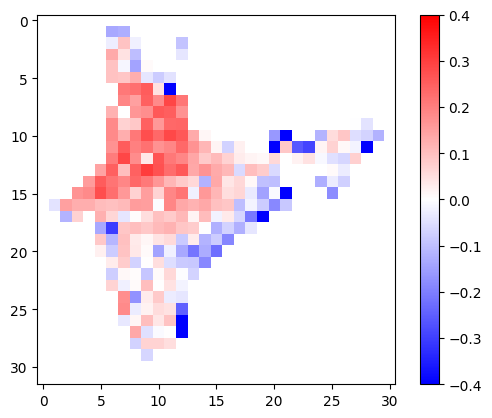

In [85]:
# old_index = np.argwhere(week_1_old_rpss==0)
plt.imshow(np.flip(week_2_old_rpss, axis=0), cmap='bwr', vmin=-0.4, vmax=0.4)
# for i in old_index:
#     plt.plot(i[1], 31-i[0], 'g*', markersize=5)
plt.colorbar()

In [115]:
np.save('./RPSS - Scores/new_rpss_mat_randomized.npy', new_rpss_mat)

In [32]:
import json
import ast

In [33]:
# Read dictionary from a JSON file
with open('best_params_2.json', 'r') as json_file:
    params_str_keys = json.load(json_file)

# Convert string keys back to tuples
best_params_prop = {ast.literal_eval(k): v for k, v in params_str_keys.items()}

In [34]:
# Read dictionary from a JSON file
with open('best_params_extr_2.json', 'r') as json_file:
    params_str_keys = json.load(json_file)

# Convert string keys back to tuples
best_params_prop1 = {ast.literal_eval(k): v for k, v in params_str_keys.items()}

In [35]:
for i in best_params_prop1:
    best_params_prop[i] = best_params_prop1[i]

In [36]:
new_rpss_mat = np.full((32,31), np.nan)
terciles = np.full((32,31,140,3), np.nan)
ohe_mat = np.zeros((32,31,140,3))
for i in tqdm(best_params_prop):
    try:
        if np.all(np.isnan(y_train[:, i[0], i[1]])):
            print(f"Skipping {i[0], i[1]} as null...")
            continue
        ohe, _, _ = make_ohe(y_test[:, i[0], i[1]])
        ohe_mat[i[0],i[1],:,:] = ohe
        rps_c = rps_clim(ohe)
        ms, n = best_params_prop[(i[0],i[1])]['mss'], best_params_prop[(i[0],i[1])]['ne']
        tp = get_tercile_predictions_single_grid(
            y_train[:, i[0], i[1]], 
            X_train[:, i[0], i[1]], 
            y_test[:, i[0], i[1]], 
            X_test[:, i[0], i[1]], ms, n
        )
        terciles[i[0],i[1],:,:] = tp
        rps_fc = rps_forecast(ohe, tp)
        new_rpss_mat[i[0], i[1]] = 1 - (rps_fc / rps_c)
    except:
        new_rpss_mat[i[0], i[1]] = 0
        continue

100%|█████████████████████████████████████████| 316/316 [02:21<00:00,  2.23it/s]


In [37]:
best_params_prop

{(2, 9): {'mss': 80, 'ne': 50, 'b_rpss': 0.0571029797139625},
 (2, 10): {'mss': 54, 'ne': 29, 'b_rpss': 0.05172943732699942},
 (3, 8): {'mss': 41, 'ne': 21, 'b_rpss': 0.03721282856551522},
 (3, 9): {'mss': 46, 'ne': 24, 'b_rpss': 0.07041171643746202},
 (3, 10): {'mss': 55, 'ne': 20, 'b_rpss': 0.07239591307027071},
 (3, 11): {'mss': 53, 'ne': 20, 'b_rpss': 0.0610459585823796},
 (4, 8): {'mss': 54, 'ne': 27, 'b_rpss': 0.15120224351316336},
 (4, 9): {'mss': 80, 'ne': 57, 'b_rpss': 0.00636343196532263},
 (4, 10): {'mss': 77, 'ne': 44, 'b_rpss': 0.0033877855876828233},
 (4, 11): {'mss': 40, 'ne': 20, 'b_rpss': 0.011261220288215745},
 (5, 7): {'mss': 51, 'ne': 20, 'b_rpss': 0.06973265374071902},
 (5, 8): {'mss': 52, 'ne': 21, 'b_rpss': 0.028915610749441267},
 (5, 9): {'mss': 53, 'ne': 29, 'b_rpss': 0.10693306997590868},
 (5, 10): {'mss': 40, 'ne': 21, 'b_rpss': 0.046614152119980434},
 (5, 11): {'mss': 53, 'ne': 20, 'b_rpss': 0.09998648408869781},
 (6, 7): {'mss': 48, 'ne': 29, 'b_rpss': 0.19

In [38]:
np.sum(terciles.reshape(32*31,140,3)[211])

nan

In [39]:
np.sum(terciles)

nan

In [40]:
np.sum(np.eye(3)[np.argmax(terciles[10,10,:,:], axis=1)], axis=0)

array([36., 32., 72.])

In [41]:
flattened_terciles = terciles.reshape(-1, 140,3).reshape(-1,3)
mask = np.any(flattened_terciles > 0, axis=(0, 1))

nonz_terciles = flattened_terciles[mask].reshape(138880,3)

In [42]:
flattened_ohe = ohe_mat.reshape(-1,140,3).reshape(-1,3)
nonz_ohe = flattened_ohe[mask].reshape(138880,3)

In [43]:
assert flattened_terciles.shape == flattened_ohe.shape

In [158]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

def plot_calibration_with_monte_carlo(y_true, y_prob, n_bins=10, n_mc=1000, alpha=0.05):
    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=n_bins)

    plt.plot(prob_pred, prob_true, marker='o', linewidth=1, label='Calibration curve')
    plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated')

    # Monte Carlo simulation
    bin_counts = np.zeros(n_bins)
    bin_sums = np.zeros(n_bins)
    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(len(y_true)):
        bin_idx = np.digitize(y_prob[i], bin_edges) - 1
        bin_counts[bin_idx] += 1
        bin_sums[bin_idx] += y_true[i]

    bin_means = bin_sums / bin_counts
    bin_means[np.isnan(bin_means)] = 0

    mc_bounds = []
    for _ in range(n_mc):
        mc_samples = np.random.binomial(bin_counts, bin_means)
        mc_means = mc_samples / bin_counts
        mc_means[np.isnan(mc_means)] = 0
        mc_bounds.append(mc_means)

    mc_bounds = np.array(mc_bounds)
    lower_bound = np.percentile(mc_bounds, 100 * (alpha / 2), axis=0)
    upper_bound = np.percentile(mc_bounds, 100 * (1 - alpha / 2), axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    plt.fill_between(bin_centers, lower_bound, upper_bound, color='gray', alpha=0.2, label=f'{100 * (1 - alpha)}% confidence interval')

    plt.xlabel('Predicted probability')
    plt.ylabel('Fraction of positives')
    plt.title('Reliability Diagram with Monte Carlo Region of Acceptance')
    plt.legend()
    plt.show()

In [159]:
plot_calibration_with_monte_carlo(nonz_ohe, nonz_terciles)

ValueError: bad input shape (138880, 3)

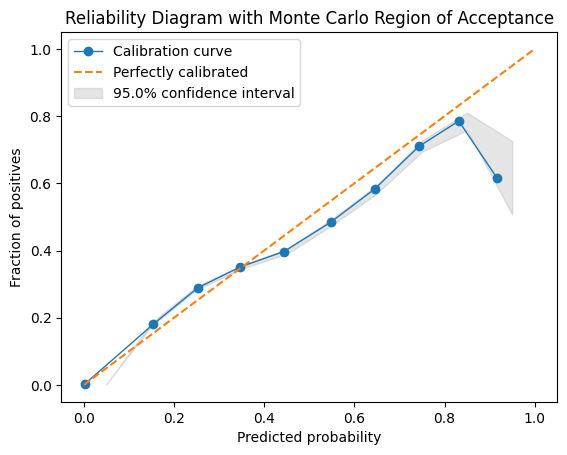

In [167]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

def plot_calibration_with_monte_carlo(y_true, y_pred, n_bins=10, n_mc=1000, alpha=0.05):
    # Flatten the input arrays
    y_true_flat = y_true.flatten()
    y_pred_flat = y_pred.flatten()

    # Ensure y_true_flat is binary (0 or 1)
    y_true_flat = y_true_flat.astype(int)

    # Compute the calibration curve
    prob_true, prob_pred = calibration_curve(y_true_flat, y_pred_flat, n_bins=n_bins)

    fig, ax = plt.subplots()

    plt.plot(prob_pred, prob_true, marker='o', linewidth=1, label='Calibration curve')
    plt.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated')

    # Monte Carlo simulation
    bin_counts = np.zeros(n_bins, dtype=int)
    bin_sums = np.zeros(n_bins, dtype=float)
    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(len(y_true_flat)):
        bin_idx = np.digitize(y_pred_flat[i], bin_edges) - 1
        if bin_idx < n_bins:  # Ensure bin_idx is within valid range
            bin_counts[bin_idx] += 1
            bin_sums[bin_idx] += y_true_flat[i]

    bin_means = bin_sums / bin_counts
    bin_means[np.isnan(bin_means)] = 0

    mc_bounds = []
    for _ in range(n_mc):
        mc_samples = np.random.binomial(bin_counts, bin_means)
        mc_means = mc_samples / bin_counts
        mc_means[np.isnan(mc_means)] = 0
        mc_bounds.append(mc_means)

    mc_bounds = np.array(mc_bounds)
    lower_bound = np.percentile(mc_bounds, 100 * (alpha / 2), axis=0)
    upper_bound = np.percentile(mc_bounds, 100 * (1 - alpha / 2), axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    plt.fill_between(bin_centers, lower_bound, upper_bound, color='gray', alpha=0.2, label=f'{100 * (1 - alpha)}% confidence interval')

    plt.xlabel('Predicted probability')
    plt.ylabel('Fraction of positives')
    plt.title('Reliability Diagram with Monte Carlo Region of Acceptance')
    plt.legend()
    plt.show()

# Example usage
# Assuming y_true and y_pred are both arrays of shape (13880, 3)
y_true = np.random.randint(0, 2, size=(13880, 3))  # Example true labels
y_pred = np.random.rand(13880, 3)  # Example predicted probabilities

plot_calibration_with_monte_carlo(nonz_ohe, nonz_terciles)

[7.12924827e-01 4.91599462e-02 7.37423195e-02 7.46711790e-02
 4.22835061e-02 2.43207565e-02 1.40120968e-02 6.50681644e-03
 2.20334101e-03 1.75211214e-04]


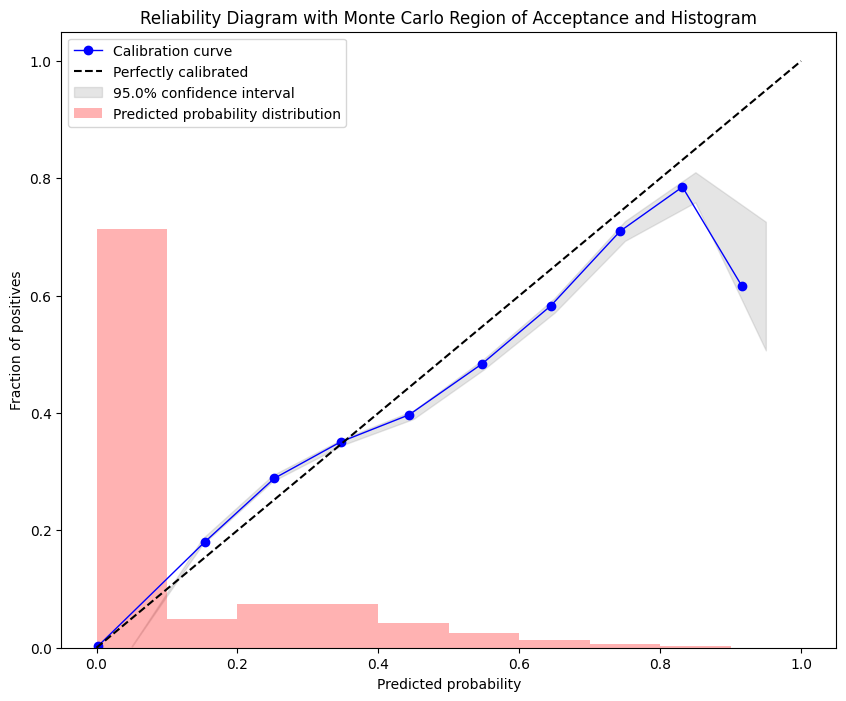

In [172]:
def plot_calibration_with_monte_carlo(y_true, y_pred, n_bins=10, n_mc=1000, alpha=0.05):
    # Flatten the input arrays
    y_true_flat = y_true.flatten()
    y_pred_flat = y_pred.flatten()

    # Ensure y_true_flat is binary (0 or 1)
    y_true_flat = y_true_flat.astype(int)

    # Compute the calibration curve
    prob_true, prob_pred = calibration_curve(y_true_flat, y_pred_flat, n_bins=n_bins)

    fig, ax1 = plt.subplots(figsize=(10, 8))

    # Plot the calibration curve
    ax1.plot(prob_pred, prob_true, marker='o', linewidth=1, label='Calibration curve', color='b')
    ax1.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated', color='black')

    # Monte Carlo simulation
    bin_counts = np.zeros(n_bins, dtype=int)
    bin_sums = np.zeros(n_bins, dtype=float)
    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(len(y_true_flat)):
        bin_idx = np.digitize(y_pred_flat[i], bin_edges) - 1
        if bin_idx < n_bins:  # Ensure bin_idx is within valid range
            bin_counts[bin_idx] += 1
            bin_sums[bin_idx] += y_true_flat[i]

    bin_means = bin_sums / bin_counts
    bin_means[np.isnan(bin_means)] = 0

    mc_bounds = []
    for _ in range(n_mc):
        mc_samples = np.random.binomial(bin_counts, bin_means)
        mc_means = mc_samples / bin_counts
        mc_means[np.isnan(mc_means)] = 0
        mc_bounds.append(mc_means)

    mc_bounds = np.array(mc_bounds)
    lower_bound = np.percentile(mc_bounds, 100 * (alpha / 2), axis=0)
    upper_bound = np.percentile(mc_bounds, 100 * (1 - alpha / 2), axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    ax1.fill_between(bin_centers, lower_bound, upper_bound, color='gray', alpha=0.2, label=f'{100 * (1 - alpha)}% confidence interval')

    # Plot the histogram on the same plot
    hist, bins = np.histogram(y_pred_flat, bins=bin_edges)
    hist = hist / y_true_flat.shape[0]  # Normalize histogram
    print(hist)
    bin_width = bins[1] - bins[0]
    ax1.bar(bins[:-1] + bin_width / 2, hist, width=bin_width, alpha=0.3, color='r', label='Predicted probability distribution')

    ax1.set_xlabel('Predicted probability')
    ax1.set_ylabel('Fraction of positives')
    ax1.set_title('Reliability Diagram with Monte Carlo Region of Acceptance and Histogram')
    ax1.legend(loc='best')

    plt.show()

plot_calibration_with_monte_carlo(nonz_ohe, nonz_terciles)

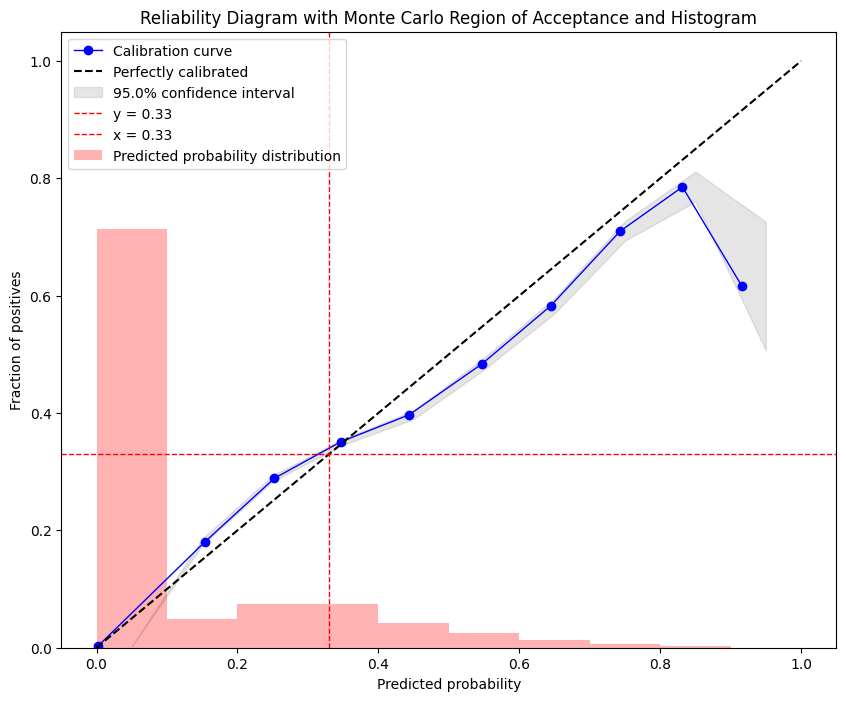

In [175]:
def plot_calibration_with_monte_carlo(y_true, y_pred, n_bins=10, n_mc=1000, alpha=0.05):
    # Flatten the input arrays
    y_true_flat = y_true.flatten()
    y_pred_flat = y_pred.flatten()

    # Ensure y_true_flat is binary (0 or 1)
    y_true_flat = y_true_flat.astype(int)

    # Compute the calibration curve
    prob_true, prob_pred = calibration_curve(y_true_flat, y_pred_flat, n_bins=n_bins)

    fig, ax1 = plt.subplots(figsize=(10, 8))

    # Plot the calibration curve
    ax1.plot(prob_pred, prob_true, marker='o', linewidth=1, label='Calibration curve', color='b')
    ax1.plot([0, 1], [0, 1], linestyle='--', label='Perfectly calibrated', color='black')

    # Monte Carlo simulation
    bin_counts = np.zeros(n_bins, dtype=int)
    bin_sums = np.zeros(n_bins, dtype=float)
    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(len(y_true_flat)):
        bin_idx = np.digitize(y_pred_flat[i], bin_edges) - 1
        if bin_idx < n_bins:  # Ensure bin_idx is within valid range
            bin_counts[bin_idx] += 1
            bin_sums[bin_idx] += y_true_flat[i]

    bin_means = bin_sums / bin_counts
    bin_means[np.isnan(bin_means)] = 0

    mc_bounds = []
    for _ in range(n_mc):
        mc_samples = np.random.binomial(bin_counts, bin_means)
        mc_means = mc_samples / bin_counts
        mc_means[np.isnan(mc_means)] = 0
        mc_bounds.append(mc_means)

    mc_bounds = np.array(mc_bounds)
    lower_bound = np.percentile(mc_bounds, 100 * (alpha / 2), axis=0)
    upper_bound = np.percentile(mc_bounds, 100 * (1 - alpha / 2), axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    ax1.fill_between(bin_centers, lower_bound, upper_bound, color='gray', alpha=0.2, label=f'{100 * (1 - alpha)}% confidence interval')

    # Plot the histogram on the same plot
    hist, bins = np.histogram(y_pred_flat, bins=bin_edges)
    hist = hist / y_true_flat.shape[0]  # Normalize histogram
    bin_width = bins[1] - bins[0]
    ax1.bar(bins[:-1] + bin_width / 2, hist, width=bin_width, alpha=0.3, color='r', label='Predicted probability distribution')

    # Add dashed red lines at 0.33 along the x-axis and y-axis
    ax1.axhline(y=0.33, color='red', linestyle='--', linewidth=1, label='y = 0.33')
    ax1.axvline(x=0.33, color='red', linestyle='--', linewidth=1, label='x = 0.33')

    ax1.set_xlabel('Predicted probability')
    ax1.set_ylabel('Fraction of positives')
    ax1.set_title('Reliability Diagram with Monte Carlo Region of Acceptance and Histogram')
    ax1.legend(loc='best')

    plt.show()
    
plot_calibration_with_monte_carlo(nonz_ohe, nonz_terciles)

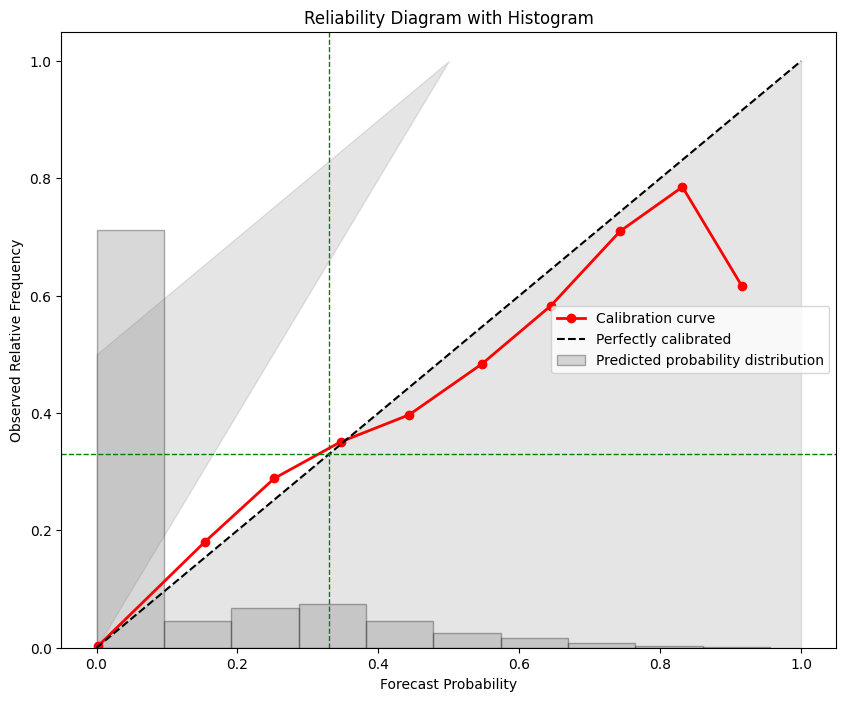

In [176]:
def plot_reliability_diagram(y_true, y_pred, n_bins=10):
    # Flatten the input arrays
    y_true_flat = y_true.flatten()
    y_pred_flat = y_pred.flatten()

    # Ensure y_true_flat is binary (0 or 1)
    y_true_flat = y_true_flat.astype(int)

    # Compute the calibration curve
    prob_true, prob_pred = calibration_curve(y_true_flat, y_pred_flat, n_bins=n_bins)

    fig, ax1 = plt.subplots(figsize=(10, 8))

    # Plot the calibration curve
    ax1.plot(prob_pred, prob_true, marker='o', linewidth=2, color='red', label='Calibration curve')
    ax1.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfectly calibrated')

    # Plotting the shaded regions
    ax1.fill_between([0, 1], [0, 1], color='gray', alpha=0.2)
    ax1.fill_between([0, 0.5], [0, 1], [0.5, 1], color='gray', alpha=0.2)

    # Plot the histogram on the same plot
    hist, bins = np.histogram(y_pred_flat, bins=n_bins)
    hist = hist / y_true_flat.shape[0]  # Normalize histogram
    bin_width = bins[1] - bins[0]
    ax1.bar(bins[:-1] + bin_width / 2, hist, width=bin_width, alpha=0.3, color='gray', edgecolor='black', label='Predicted probability distribution')

    # Add dashed red lines at 0.33 along the x-axis and y-axis
    ax1.axhline(y=0.33, color='green', linestyle='--', linewidth=1)
    ax1.axvline(x=0.33, color='green', linestyle='--', linewidth=1)

    # Set labels and titles
    ax1.set_xlabel('Forecast Probability')
    ax1.set_ylabel('Observed Relative Frequency')
    ax1.set_title('Reliability Diagram with Histogram')
    ax1.legend(loc='best')

    plt.show()
    
plot_reliability_diagram(nonz_ohe, nonz_terciles)

In [44]:
nonz_terciles_f = np.concatenate([nonz_terciles[:,0], nonz_terciles[:,1], nonz_terciles[:,2]], axis=0)

In [45]:
nonz_terciles_f.shape

(416640,)

In [46]:
nonz_ohe_f = np.concatenate([nonz_ohe[:,0], nonz_ohe[:,1], nonz_ohe[:,2]], axis=0)

In [47]:
nonz_ohe_f.shape

(416640,)

In [48]:
np.save('nonz_terciles_f_2.npy', nonz_terciles_f)
np.save('nonz_ohe_f_2.npy', nonz_ohe_f)

In [184]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def plot_reliability_diagram_with_monte_carlo(y_true, y_pred, n_bins=10, n_mc=1000, alpha=0.05):
    # Compute the calibration curve
    prob_true, prob_pred = calibration_curve(y_true, y_pred, n_bins=n_bins)

    fig, ax1 = plt.subplots(figsize=(10, 8))

    # Plot the calibration curve
    ax1.plot(prob_pred, prob_true, marker='o', linewidth=2, color='red', label='Calibration curve')
    ax1.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfectly calibrated')

    # Monte Carlo simulation to calculate confidence intervals
    bin_counts = np.zeros(n_bins, dtype=int)
    bin_sums = np.zeros(n_bins, dtype=float)
    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(len(y_true)):
        bin_idx = np.digitize(y_pred[i], bin_edges) - 1
        if bin_idx < n_bins:  # Ensure bin_idx is within valid range
            bin_counts[bin_idx] += 1
            bin_sums[bin_idx] += y_true[i]

    bin_means = bin_sums / bin_counts
    bin_means[np.isnan(bin_means)] = 0

    mc_bounds = []
    for _ in range(n_mc):
        mc_samples = np.random.binomial(bin_counts, bin_means)
        mc_means = mc_samples / bin_counts
        mc_means[np.isnan(mc_means)] = 0
        mc_bounds.append(mc_means)

    mc_bounds = np.array(mc_bounds)
    lower_bound = np.percentile(mc_bounds, 100 * (alpha / 2), axis=0)
    upper_bound = np.percentile(mc_bounds, 100 * (1 - alpha / 2), axis=0)

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Plot the shaded regions for confidence intervals
    ax1.fill_between(bin_centers, lower_bound, upper_bound, color='gray', alpha=0.2, label=f'{100 * (1 - alpha)}% confidence interval')

    # Plot the histogram on the same plot
    hist, bins = np.histogram(y_pred, bins=n_bins)
    hist = hist / y_true.shape[0]  # Normalize histogram
    bin_width = bins[1] - bins[0]
    ax1.bar(bins[:-1] + bin_width / 2, hist, width=bin_width, alpha=0.3, color='gray', edgecolor='black', label='Predicted probability distribution')

    # Add dashed red lines at 0.33 along the x-axis and y-axis
    ax1.axhline(y=0.33, color='green', linestyle='--', linewidth=1)
    ax1.axvline(x=0.33, color='green', linestyle='--', linewidth=1)

    # Set labels and titles
    ax1.set_xlabel('Forecast Probability')
    ax1.set_ylabel('Observed Relative Frequency')
    ax1.set_title('Reliability Diagram with Histogram')
    ax1.legend(loc='best')

    plt.show()

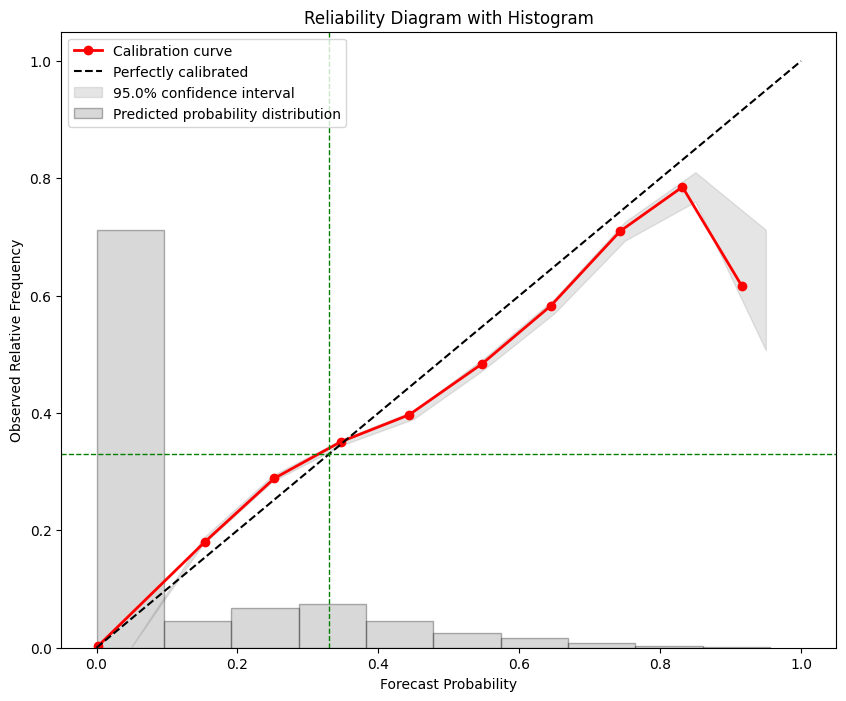

In [185]:
plot_reliability_diagram_with_monte_carlo(nonz_ohe_f, nonz_terciles_f)

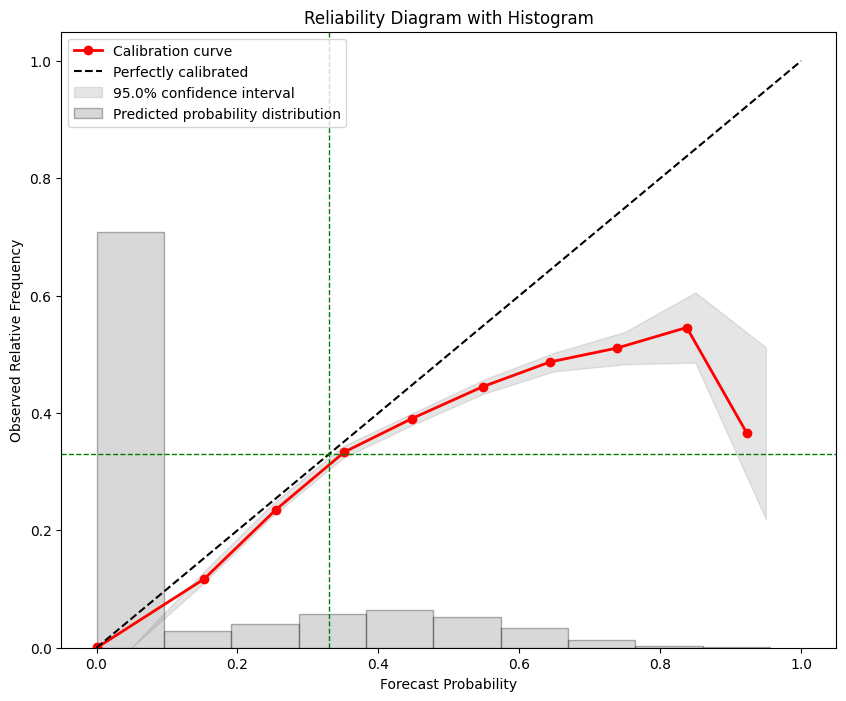

In [187]:
plot_reliability_diagram_with_monte_carlo(nonz_ohe[:,2], nonz_terciles[:,2])

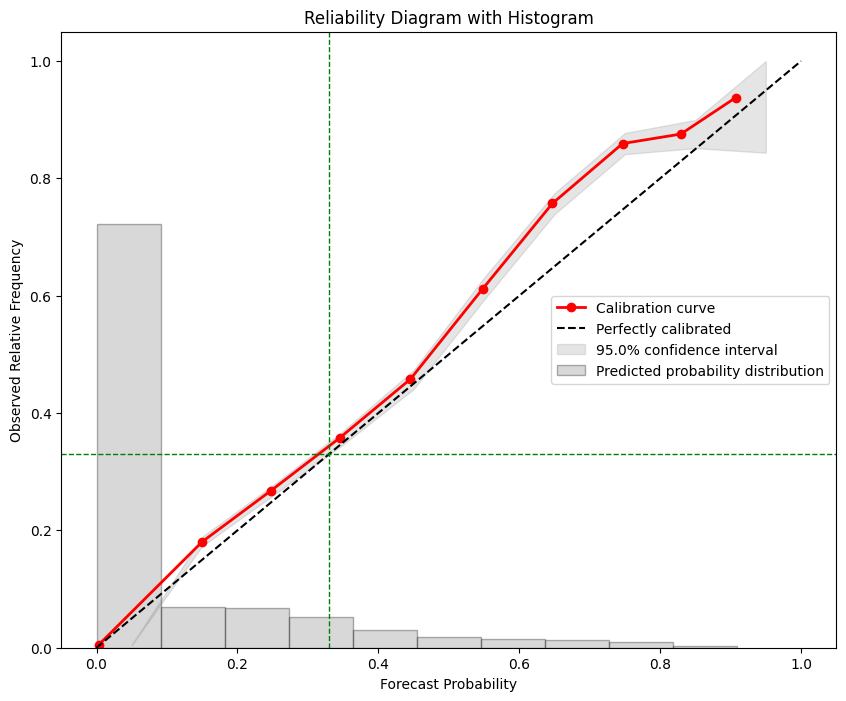

In [188]:
plot_reliability_diagram_with_monte_carlo(nonz_ohe[:,0], nonz_terciles[:,0])

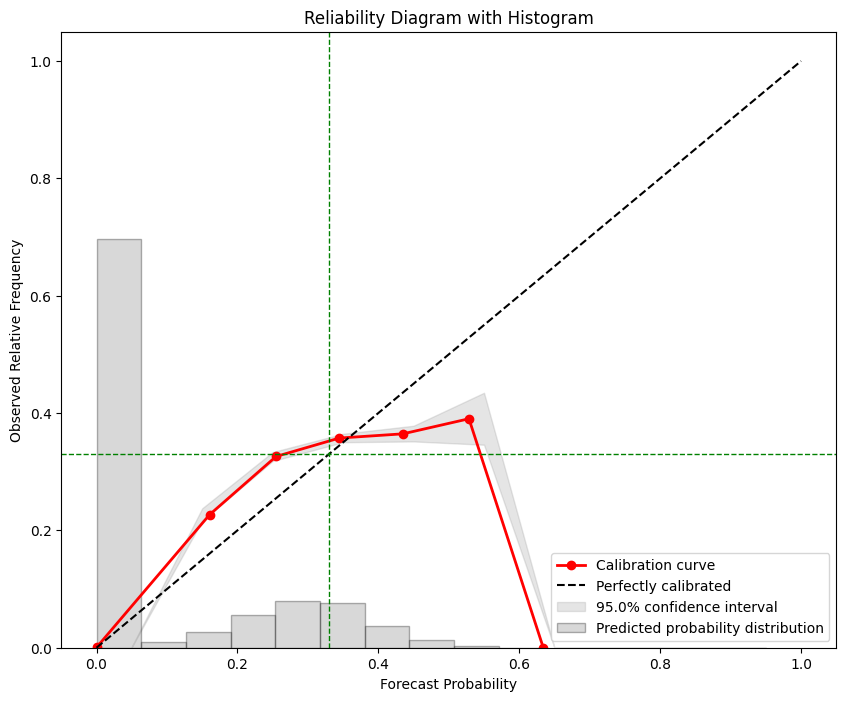

In [189]:
plot_reliability_diagram_with_monte_carlo(nonz_ohe[:,1], nonz_terciles[:,1])

In [46]:
np.save('nonz_terciles_f.npy', nonz_terciles_f)

In [47]:
np.save('nonz_ohe_f.npy', nonz_ohe_f)

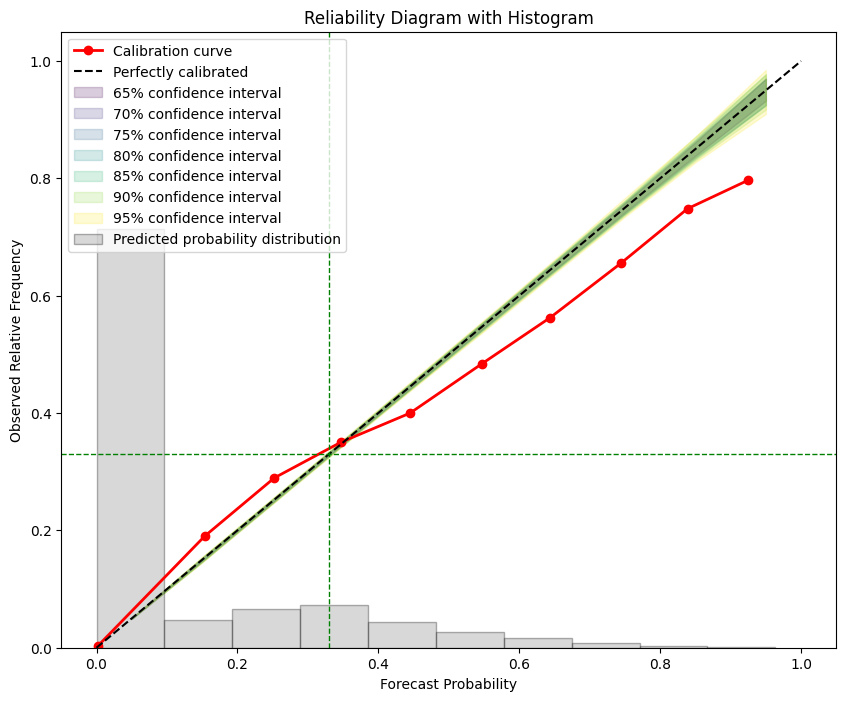

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

def plot_reliability_diagram_with_monte_carlo(y_true, y_pred, n_bins=10, n_mc=1000):
    # Compute the calibration curve
    prob_true, prob_pred = calibration_curve(y_true, y_pred, n_bins=n_bins)

    fig, ax1 = plt.subplots(figsize=(10, 8))

    # Plot the calibration curve
    ax1.plot(prob_pred, prob_true, marker='o', linewidth=2, color='red', label='Calibration curve')
    ax1.plot([0, 1], [0, 1], linestyle='--', color='black', label='Perfectly calibrated')

    # Monte Carlo simulation to calculate confidence intervals on the perfect reliability line
    bin_counts = np.zeros(n_bins, dtype=int)
    bin_edges = np.linspace(0, 1, n_bins + 1)

    for i in range(len(y_true)):
        bin_idx = np.digitize(y_pred[i], bin_edges) - 1
        if bin_idx < n_bins:  # Ensure bin_idx is within valid range
            bin_counts[bin_idx] += 1

    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Calculate confidence intervals for each specified level
    confidence_intervals = list(range(65, 100, 5))
    colors = plt.cm.viridis(np.linspace(0, 1, len(confidence_intervals)))

    for conf, color in zip(confidence_intervals, colors):
        lower_bounds = []
        upper_bounds = []

        for _ in range(n_mc):
            mc_samples = np.random.binomial(bin_counts, bin_centers)
            mc_means = mc_samples / bin_counts
            mc_means[np.isnan(mc_means)] = 0
            lower_bounds.append(mc_means)
            upper_bounds.append(mc_means)

        lower_bounds = np.percentile(lower_bounds, 100 * (1 - conf / 100) / 2, axis=0)
        upper_bounds = np.percentile(upper_bounds, 100 * (1 + conf / 100) / 2, axis=0)

        # Plot the shaded regions for each confidence interval
        ax1.fill_between(bin_centers, lower_bounds, upper_bounds, color=color, alpha=0.2, label=f'{conf}% confidence interval')

    # Plot the histogram on the same plot
    hist, bins = np.histogram(y_pred, bins=n_bins)
    hist = hist / y_true.shape[0]  # Normalize histogram
    bin_width = bins[1] - bins[0]
    ax1.bar(bins[:-1] + bin_width / 2, hist, width=bin_width, alpha=0.3, color='gray', edgecolor='black', label='Predicted probability distribution')

    # Add dashed red lines at 0.33 along the x-axis and y-axis
    ax1.axhline(y=0.33, color='green', linestyle='--', linewidth=1)
    ax1.axvline(x=0.33, color='green', linestyle='--', linewidth=1)

    # Set labels and titles
    ax1.set_xlabel('Forecast Probability')
    ax1.set_ylabel('Observed Relative Frequency')
    ax1.set_title('Reliability Diagram with Histogram')
    ax1.legend(loc='best')

    plt.show()

plot_reliability_diagram_with_monte_carlo(nonz_ohe_f, nonz_terciles_f)